In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Use the path matching the notebook's working directory:
path = Path("../data/processed/zev_county_year.csv")  # if cwd is notebooks/
# path = Path("data/processed/zev_county_year.csv")  # if cwd is the project root

df = pd.read_csv(path)

In [2]:
print(df.shape)

(1102, 7)


In [3]:
annual = (
    df.groupby("year", as_index=False)
      .agg(
          counties=("county", "nunique"),
          n_quarters=("n_quarters", "max"),
          zev_sales=("zev_total", "sum"),
      )
)

annual

,year,counties,n_quarters,zev_sales
0,2008,58,2,73
1,2009,58,4,502
2,2010,58,4,235
3,2011,58,4,5798
4,2012,58,4,16320
5,2013,58,4,37080
6,2014,58,4,55219
7,2015,58,4,54160
8,2016,58,4,68746
9,2017,58,4,89569


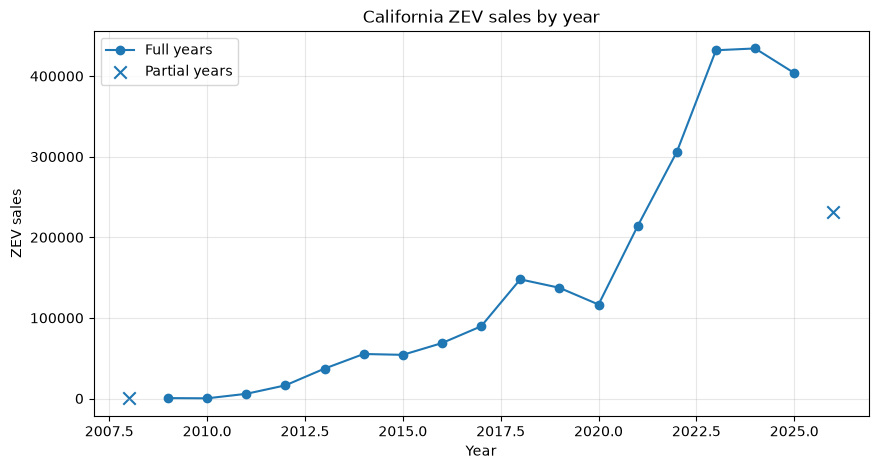

In [4]:
complete = annual[annual["n_quarters"] == 4]
partial = annual[annual["n_quarters"] < 4]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(complete["year"], complete["zev_sales"], marker="o", label="Full years")
ax.scatter(partial["year"], partial["zev_sales"], marker="x", s=80,
           label="Partial years")

ax.set(title="California ZEV sales by year",
       xlabel="Year", ylabel="ZEV sales")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()